# Исследование: информативность признаков для XGBoost

Протокол — `research.md` (Obsidian vault). Проверка работоспособности
библиотеки на открытом датасете **Dry Bean** (UCI): 13 611 объектов,
16 числовых геометрических признаков зёрен, 7 сортов фасоли.
Признаки сильно коррелированы (площадь, периметр, оси, диаметр), поэтому
датасет удобен и для фильтра корреляций.

Этапы:
1. Загрузка, разбиение на A / B / C.
2. Корреляционный анализ на A и удаление признаков с |r| > порога.
3. Информативность на A (`ImportanceEvaluator`): MI, ANOVA F, MDI, PI, SHAP — все на XGBoost (L1 не считается: он только для LogReg).
4. Кривые качества на B (`ModelValidator`) и выбор N.
5. Финальная проверка на C: выбранные наборы против baseline.
6. Сохранение результатов.

Перебор (`FeatureSelector`) и статистика (`StatisticalAnalyzer`) — после реализации `selection.py` и `statistics.py`.

In [1]:
import json
import logging
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import get_scorer
from sklearn.model_selection import StratifiedKFold, train_test_split

from common import load_data, make_xgb
from importance import ImportanceEvaluator
from validation import ModelValidator

logging.basicConfig(level=logging.INFO, format="%(name)s: %(message)s")

## 0. Параметры исследования

Все параметры — здесь, вне классов (`research.md`, раздел 2).

In [7]:
# --- данные ---
DATA_PATH = "data/dry_bean.csv"
TARGET_COL = "Class"
SEED = 42                     # разбиение A/B/C, сплиттеры

# --- доли наборов A / B / C ---
FRAC_A, FRAC_B, FRAC_C = 1 / 3, 1 / 3, 1 / 3

# --- фильтр корреляций (считается только на A) ---
CORR_FILTER = True
CORR_METHOD = "pearson"       # 'pearson' | 'spearman'
CORR_THRESHOLD = 1

# --- CV ---
cv_A = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_B = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
N_RUNS = 2                    # прогоны ImportanceEvaluator

# --- модель ---
# n_jobs=1: параллелится цикл по фолдам в классах библиотеки.
XGB_PARAMS = dict(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=1)


def model_factory(seed):
    return make_xgb(seed, **XGB_PARAMS)


# --- метрики ---
PI_SCORING = ["roc_auc_ovr", "balanced_accuracy"]   # permutation importance
VAL_SCORING = ["f1_macro", "roc_auc_ovr"]           # кривые на B, проверка на C
MAIN_METRIC = "f1_macro"                            # по ней выбирается N
N_RULE = "1se"                                      # 'max' | '1se'

# --- финальная проверка: на чём обучать модель перед оценкой на C ---
FINAL_TRAIN = "AB"            # 'AB' | 'B'

RESULTS_DIR = "results/xgb_dry_bean"

## 1. Загрузка и разбиение

CSV готовится один раз из оригинального архива UCI. Групп нет, поэтому
разбиение — два последовательных стратифицированных `train_test_split`.

In [8]:
if not os.path.exists(DATA_PATH):
    os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
    zip_path, _ = urllib.request.urlretrieve(url)
    with zipfile.ZipFile(zip_path) as z:
        with z.open("DryBeanDataset/Dry_Bean_Dataset.xlsx") as f:
            pd.read_excel(f).to_csv(DATA_PATH, index=False)

X, y, feature_names, groups, classes = load_data(DATA_PATH, TARGET_COL)
print(X.shape, list(classes))

otbor.common: Загружен data/dry_bean.csv: 13611 строк, 17 колонок


otbor.common: Кодирование классов (исходная метка -> код): 'BARBUNYA' -> 0 (n=1322), 'BOMBAY' -> 1 (n=522), 'CALI' -> 2 (n=1630), 'DERMASON' -> 3 (n=3546), 'HOROZ' -> 4 (n=1928), 'SEKER' -> 5 (n=2027), 'SIRA' -> 6 (n=2636)
otbor.common: Итог: n=13611, признаков=16, классов=7


(13611, 16) ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [9]:
idx = np.arange(len(y))
rest, C = train_test_split(idx, test_size=FRAC_C, stratify=y,
                           random_state=SEED)
A, B = train_test_split(rest, test_size=FRAC_B / (1 - FRAC_C),
                        stratify=y[rest], random_state=SEED)

# Проверка: наборы не пересекаются, все классы есть в каждом.
assert not (set(A) & set(B) or set(A) & set(C) or set(B) & set(C))
for name, part in [("A", A), ("B", B), ("C", C)]:
    assert len(np.unique(y[part])) == len(classes), name

pd.DataFrame(
    {name: np.bincount(y[part], minlength=len(classes))
     for name, part in [("A", A), ("B", B), ("C", C)]},
    index=classes,
).assign(total=lambda d: d.sum(axis=1))

,A,B,C,total
BARBUNYA,441,441,440,1322
BOMBAY,174,174,174,522
CALI,543,544,543,1630
DERMASON,1182,1182,1182,3546
HOROZ,643,642,643,1928
SEKER,675,676,676,2027
SIRA,879,878,879,2636


## 2. Корреляционный анализ (на A)

Считается только на A: B и C в выборе признаков не участвуют.

Жадное удаление: пока есть пара с |r| > порога, удаляется признак с
наибольшим числом таких пар (при равенстве — с большим средним |r|).
Так из группы взаимно коррелированных признаков остаётся один,
и результат не зависит от порядка колонок.

In [10]:
def correlation_filter(df, threshold, method="pearson"):
    # Возвращает (оставленные признаки, удалённые признаки в порядке удаления).
    corr = df.corr(method=method).abs()
    corr = corr.mask(np.eye(len(corr), dtype=bool), 0.0)   # без диагонали
    dropped = []
    while True:
        high = corr > threshold
        counts = high.sum(axis=1)
        if counts.max() == 0:
            break
        candidates = counts[counts == counts.max()].index
        worst = corr.loc[candidates].mean(axis=1).idxmax()
        dropped.append(worst)
        corr = corr.drop(index=worst, columns=worst)
    return list(corr.columns), dropped


df_A = pd.DataFrame(X[A], columns=feature_names)
corr_A = df_A.corr(method=CORR_METHOD)

if CORR_FILTER:
    kept, dropped = correlation_filter(df_A, CORR_THRESHOLD, CORR_METHOD)
else:
    kept, dropped = list(feature_names), []
print(f"Оставлено {len(kept)} из {len(feature_names)}: {kept}")
print(f"Удалено: {dropped}")

Оставлено 16 из 16: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Удалено: []


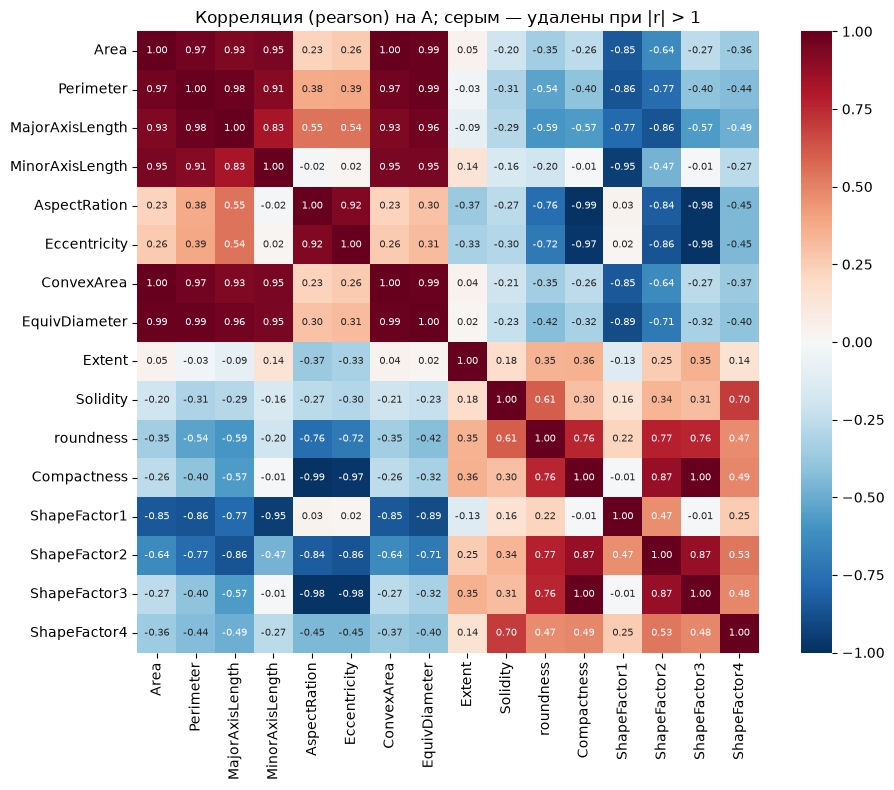

In [11]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_A, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 7}, square=True, ax=ax)
# Удалённые признаки — серым на осях.
for label in ax.get_xticklabels() + ax.get_yticklabels():
    if label.get_text() in dropped:
        label.set_color("grey")
ax.set_title(f"Корреляция ({CORR_METHOD}) на A; серым — удалены при |r| > {CORR_THRESHOLD}")
plt.tight_layout()
plt.show()

In [12]:
# Дальше работаем только с оставленными признаками.
cols = [feature_names.index(f) for f in kept]
X_sel = X[:, cols]
features = kept
X_A, y_A = X_sel[A], y[A]
X_B, y_B = X_sel[B], y[B]
X_C, y_C = X_sel[C], y[C]

## 3. Информативность на A

Все методы — на одних и тех же фолдах `cv_A` (ранжирования парные).
SHAP для XGBoost — по логитам (`model_output='raw'`, TreeExplainer):
вероятности бустингов shap объясняет неверно.

In [13]:
ev = ImportanceEvaluator(X_A, y_A, features, cv=cv_A, n_runs=N_RUNS,
                         random_state=SEED)
(ev.compute_mi("mi")
   .compute_anova_f("anova_f")
   .compute_mdi(model_factory, "mdi_xgb")
   .compute_pi(model_factory, "pi_xgb", scoring=PI_SCORING)
   .compute_shap(model_factory, "shap_xgb", model_output="raw"))

labels = list(ev.importance_results)
labels

otbor.importance: mi: готово
otbor.importance: anova_f: готово
otbor.importance: mdi_xgb: готово
otbor.importance: pi_xgb: готово
100%|===================| 6347/6356 [13:04<00:01]        otbor.importance: shap_xgb: готово


['mi',
 'anova_f',
 'mdi_xgb',
 'pi_xgb_roc_auc_ovr',
 'pi_xgb_balanced_accuracy',
 'shap_xgb']

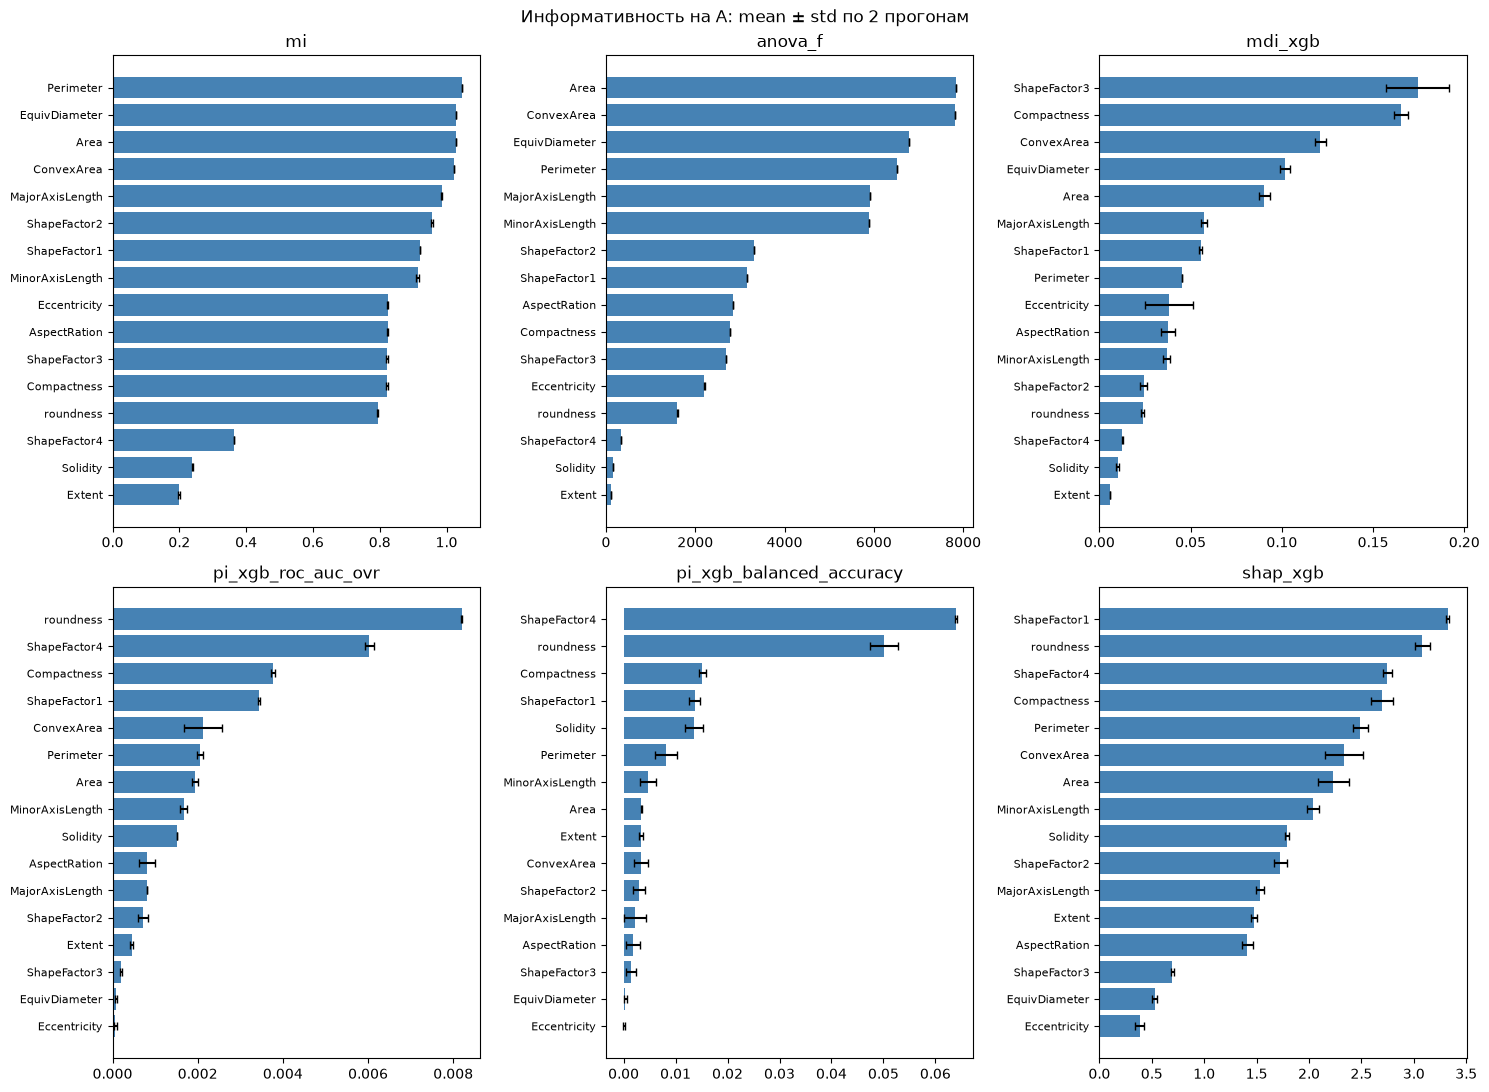

In [14]:
ncols = 3
nrows = int(np.ceil(len(labels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 0.3 * len(features) * nrows + 1.5),
                         squeeze=False)
for ax, label in zip(axes.flat, labels):
    r = ev.get_ranking(label)[::-1]    # наибольшее — сверху
    ax.barh(r["feature"], r[f"{label}_mean"], xerr=r[f"{label}_std"],
            color="steelblue", ecolor="black", capsize=3)
    ax.set_title(label)
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(labels):]:
    ax.set_visible(False)
fig.suptitle(f"Информативность на A: mean ± std по {N_RUNS} прогонам")
plt.tight_layout()
plt.show()

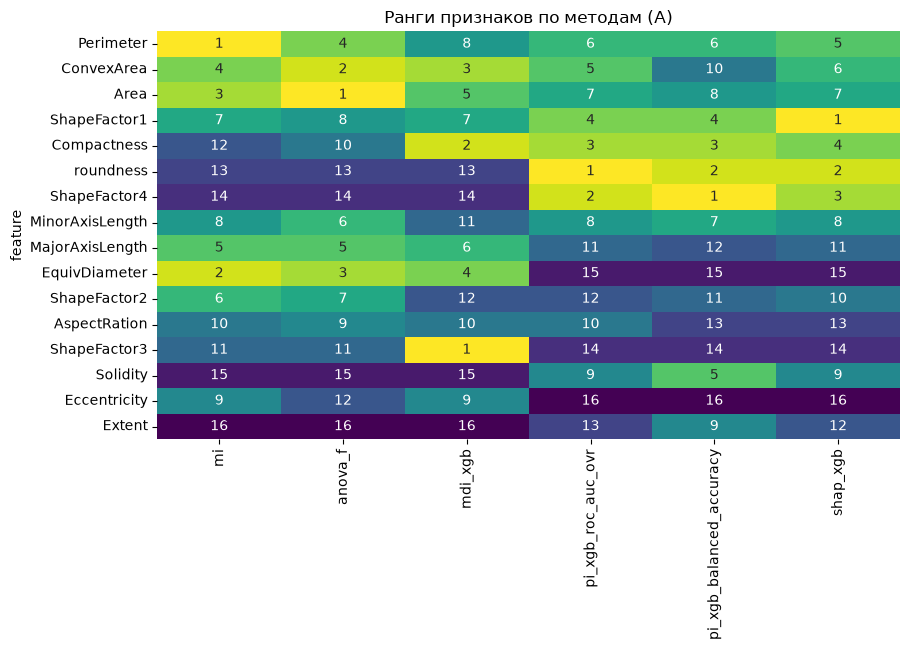

In [15]:
# Ранги признаков по методам (1 — самый информативный).
ranks = pd.DataFrame({
    label: ev.importance_results[label].set_index("feature")[f"{label}_mean"]
    .rank(ascending=False, method="min").astype(int)
    for label in labels
})
ranks = ranks.loc[ranks.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(1.2 * len(labels) + 2, 0.35 * len(features) + 1))
sns.heatmap(ranks, annot=True, fmt="d", cmap="viridis_r", cbar=False, ax=ax)
ax.set_title("Ранги признаков по методам (A)")
plt.tight_layout()
plt.show()

## 4. Кривые качества на B

Для каждого ранжирования из A: XGBoost на топ-N признаков, N = 1..p,
на одном фиксированном `cv_B`. Полоса — ± std по фолдам; маркер —
N, выбранное по правилу `N_RULE` на `MAIN_METRIC`.

In [16]:
ns = range(1, len(features) + 1)
val = ModelValidator(X_B, y_B, features, cv=cv_B, random_state=SEED)
for label in labels:
    val.evaluate_model_on_subsets(model_factory, ev.get_ranking(label),
                                  f"val_{label}", scoring=VAL_SCORING, ns=ns)

otbor.validation: val_mi: готово
otbor.validation: val_anova_f: готово
otbor.validation: val_mdi_xgb: готово
otbor.validation: val_pi_xgb_roc_auc_ovr: готово
otbor.validation: val_pi_xgb_balanced_accuracy: готово
otbor.validation: val_shap_xgb: готово


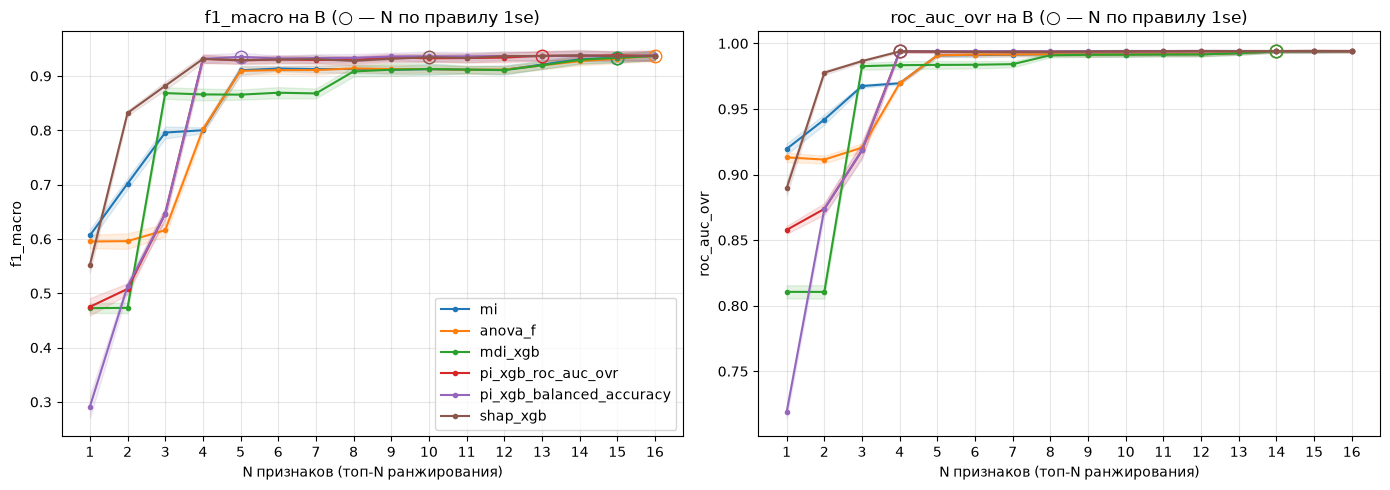

In [17]:
fig, axes = plt.subplots(1, len(VAL_SCORING), figsize=(7 * len(VAL_SCORING), 5),
                         squeeze=False)
for ax, metric in zip(axes[0], VAL_SCORING):
    for label in labels:
        s = val.get_validation_summary(f"val_{label}")
        mean, std = s[f"{metric}_mean"], s[f"{metric}_std"]
        line, = ax.plot(s["n_features"], mean, marker=".", label=label)
        ax.fill_between(s["n_features"], mean - std, mean + std,
                        color=line.get_color(), alpha=0.12)
        n_opt = val.get_optimal_n_features(f"val_{label}", metric, N_RULE)
        ax.plot(n_opt, mean[s["n_features"] == n_opt].iloc[0], marker="o",
                markersize=9, markerfacecolor="none", color=line.get_color())
    ax.set_xlabel("N признаков (топ-N ранжирования)")
    ax.set_ylabel(metric)
    ax.set_xticks(list(ns))
    ax.grid(alpha=0.3)
    ax.set_title(f"{metric} на B (○ — N по правилу {N_RULE})")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [18]:
# Выбранные N и наборы.
choice = pd.DataFrame([
    {
        "method": label,
        "n_max": val.get_optimal_n_features(f"val_{label}", MAIN_METRIC, "max"),
        "n_1se": val.get_optimal_n_features(f"val_{label}", MAIN_METRIC, "1se"),
        "subset": val.get_best_subset(f"val_{label}", MAIN_METRIC, N_RULE),
    }
    for label in labels
]).set_index("method")
choice

,n_max,n_1se,subset
method,,,
mi,16,15,"[Perimeter, EquivDiameter, Area, ConvexArea, M..."
anova_f,16,16,"[Area, ConvexArea, EquivDiameter, Perimeter, M..."
mdi_xgb,16,15,"[ShapeFactor3, Compactness, ConvexArea, EquivD..."
pi_xgb_roc_auc_ovr,15,13,"[roundness, ShapeFactor4, Compactness, ShapeFa..."
pi_xgb_balanced_accuracy,16,5,"[ShapeFactor4, roundness, Compactness, ShapeFa..."
shap_xgb,14,10,"[ShapeFactor1, roundness, ShapeFactor4, Compac..."


## 5. Финальная проверка на C

Выполняется один раз. Модель обучается на `FINAL_TRAIN` (A+B или B)
на выбранном наборе и оценивается на C. Baseline: все исходные признаки
и все признаки после фильтра корреляций. Seed модели фиксирован.

In [19]:
train_idx = np.concatenate([A, B]) if FINAL_TRAIN == "AB" else B

subsets = {"all_features": list(feature_names), "after_corr_filter": features}
subsets.update({label: choice.loc[label, "subset"] for label in labels})

rows = []
for name, subset in subsets.items():
    c = [feature_names.index(f) for f in subset]
    model = model_factory(SEED).fit(X[np.ix_(train_idx, c)], y[train_idx])
    row = {"set": name, "n_features": len(subset)}
    for metric in VAL_SCORING:
        row[metric] = get_scorer(metric)(model, X[np.ix_(C, c)], y[C])
    rows.append(row)

final = pd.DataFrame(rows).set_index("set")
final

,n_features,f1_macro,roc_auc_ovr
set,,,
all_features,16,0.936718,0.995140
after_corr_filter,16,0.936718,0.995140
mi,15,0.935952,0.994932
anova_f,16,0.936274,0.995088
mdi_xgb,15,0.935231,0.994940
pi_xgb_roc_auc_ovr,13,0.935101,0.995182
pi_xgb_balanced_accuracy,5,0.936297,0.994572
shap_xgb,10,0.935566,0.994888


## 6. Сохранение

In [ ]:
os.makedirs(RESULTS_DIR, exist_ok=True)

np.savez(f"{RESULTS_DIR}/split_indices.npz", A=A, B=B, C=C)
with open(f"{RESULTS_DIR}/params.json", "w") as f:
    json.dump({
        "data_path": DATA_PATH, "target_col": TARGET_COL, "seed": SEED,
        "fracs": [FRAC_A, FRAC_B, FRAC_C],
        "corr_filter": CORR_FILTER, "corr_method": CORR_METHOD,
        "corr_threshold": CORR_THRESHOLD,
        "kept_features": features, "dropped_features": dropped,
        "cv_A": repr(cv_A), "cv_B": repr(cv_B), "n_runs": N_RUNS,
        "xgb_params": XGB_PARAMS, "pi_scoring": PI_SCORING,
        "val_scoring": VAL_SCORING, "main_metric": MAIN_METRIC,
        "n_rule": N_RULE, "final_train": FINAL_TRAIN,
    }, f, ensure_ascii=False, indent=2)

for label in labels:
    ev.get_ranking(label).to_csv(f"{RESULTS_DIR}/ranking_{label}.csv", index=False)
    val.get_validation_summary(f"val_{label}").to_csv(
        f"{RESULTS_DIR}/curve_{label}.csv", index=False)
np.savez(f"{RESULTS_DIR}/raw_importance.npz", **ev.raw_importance)
choice.to_json(f"{RESULTS_DIR}/choice.json", force_ascii=False, indent=2)
final.to_csv(f"{RESULTS_DIR}/final_C.csv")
print(sorted(os.listdir(RESULTS_DIR)))